In [1]:
# pip install git+https://github.com/allixender/dggrid4py.git

In [2]:
import os
import dggrid4py

dggrid4py.__version__



'0.7.2'

In [3]:

import geopandas
import shapely

from dggrid4py import DGGRIDv7

# just checking if you remembered the DGGRID executable path :-)
dggrid_exec = '/data/sahel_cube/dggs/.pixi/envs/geopython2025/bin/dggrid'
# dggrid_exec = os.getenv('DGGRID')
print(dggrid_exec)

# create an inital instance that knows where the dggrid tool lives, 
# configure temp workspace and log/stdout output
dggrid_instance = DGGRIDv7(executable=dggrid_exec,
                            working_dir='.',
                            capture_logs=False,
                            silent=False,
                            tmp_geo_out_legacy=False,
                            debug=False)

# global ISEA4T grid at resolution 5 into GeoDataFrame to Shapefile
gdf1 = dggrid_instance.grid_cell_polygons_for_extent('ISEA4T', 5)
print(gdf1.head())

/data/sahel_cube/dggs/.pixi/envs/geopython2025/bin/dggrid
** executing DGGRID version 8.44 with GDAL version 3120300 **
type sizes: big int: 64 bits / big double: 128 bits

** using meta file metafile_70763908-6296-427f-83b6-8cfab63fba7e...
* parameter values:
dggrid_operation GENERATE_GRID (user set)
rng_type RAND (default)
precision 7 (user set)
verbosity 0 (default)
pause_on_startup false (default)
pause_before_exit false (default)
update_frequency 100000 (default)
dggs_type ISEA4T (user set)
dggs_topology TRIANGLE (user set)
dggs_proj ISEA (user set)
dggs_aperture_type PURE (user set)
dggs_aperture 4 (user set)
proj_datum WGS84_AUTHALIC_SPHERE (default)
dggs_orient_specify_type SPECIFIED (user set)
dggs_num_placements 1 (user set)
dggs_vert0_lon 11.25 (user set)
dggs_vert0_lat 58.2825 (user set)
dggs_vert0_azimuth 0 (user set)
dggs_res_specify_type SPECIFIED (user set)
dggs_res_spec 5 (user set)
z3_invalid_digit 0 (default)
input_files vals.txt (default)
input_file_name valsin.txt 

/tmp/ipykernel_343444/1512479608.py:13: DeprecationWarning: DGGRIDv7 is deprecated since dggrid4py 0.6.0 and will be removed in version 0.8.0, use DGGRIDv8 with DGGRID 8.42 or newer (it maps the former address types like 'Z7_STRING')
  dggrid_instance = DGGRIDv7(executable=dggrid_exec,



** grid generation complete **
* generated 20,480 cells

    name                                           geometry
0  15684  POLYGON ((165.18812 -80.91522, 169.74304 -79.0...
1  15619  POLYGON ((175.62838 -82.60082, 165.18812 -80.9...
2  15555  POLYGON ((169.95254 -84.53265, 158.28744 -82.6...
3  15620  POLYGON ((158.28744 -82.69587, 165.18812 -80.9...
4  15685  POLYGON ((165.18812 -80.91522, 158.10524 -79.0...


In [4]:
print(gdf1.head())

gdf1.to_file('isea4t_5.geojson', driver='GeoJSON')

gdf_centroids = dggrid_instance.grid_cell_centroids_for_extent(dggs_type='ISEA7H',
                                resolution=4,
                                mixed_aperture_level=None,
                                clip_geom=None)
print(gdf_centroids.head())


    name                                           geometry
0  15684  POLYGON ((165.18812 -80.91522, 169.74304 -79.0...
1  15619  POLYGON ((175.62838 -82.60082, 165.18812 -80.9...
2  15555  POLYGON ((169.95254 -84.53265, 158.28744 -82.6...
3  15620  POLYGON ((158.28744 -82.69587, 165.18812 -80.9...
4  15685  POLYGON ((165.18812 -80.91522, 158.10524 -79.0...
** executing DGGRID version 8.44 with GDAL version 3120300 **
type sizes: big int: 64 bits / big double: 128 bits

** using meta file metafile_09488120-a9e9-4113-ac2d-1a82452d0254...
* parameter values:
dggrid_operation GENERATE_GRID (user set)
rng_type RAND (default)
precision 7 (user set)
verbosity 0 (default)
pause_on_startup false (default)
pause_before_exit false (default)
update_frequency 100000 (default)
dggs_type ISEA7H (user set)
dggs_topology HEXAGON (user set)
dggs_proj ISEA (user set)
dggs_aperture_type PURE (user set)
dggs_aperture 7 (user set)
proj_datum WGS84_AUTHALIC_SPHERE (default)
dggs_orient_specify_type SPECIFIE

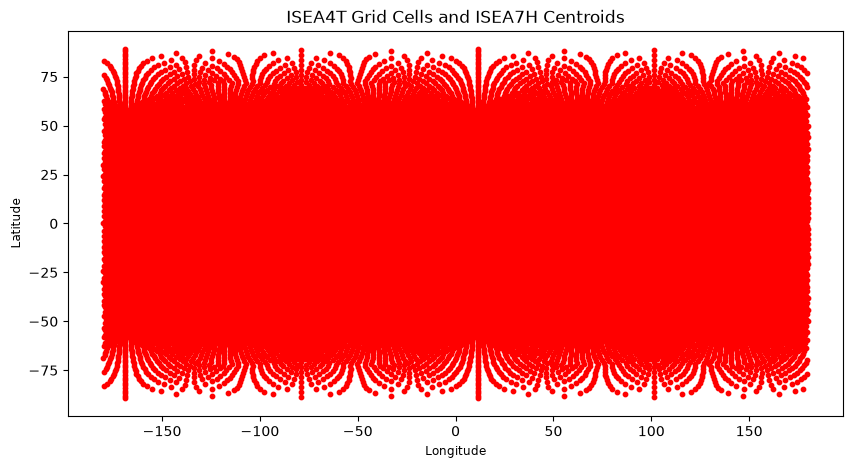

In [5]:
# plot the geojson nicely with matplotlib
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
# gdf1.plot(ax=ax, color='lightblue', edgecolor='black', alpha=0.5)
gdf_centroids.plot(ax=ax, color='red', markersize=10)
plt.title('ISEA4T Grid Cells and ISEA7H Centroids')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [6]:
# generate cell and areal statistics for a ISEA7H grids from
# resolution 0 to 8 (return a pandas DataFrame)
df1 = dggrid_instance.grid_stats_table('ISEA7H', 8)
print(df1.head(8))
df1.to_csv('isea7h_8_stats.csv', index=False)

** executing DGGRID version 8.44 with GDAL version 3120300 **
type sizes: big int: 64 bits / big double: 128 bits

** using meta file metafile_18579b01-d8bb-461a-855c-2e1b97996439...
* parameter values:
dggrid_operation OUTPUT_STATS (user set)
rng_type RAND (default)
precision 7 (user set)
verbosity 0 (default)
pause_on_startup false (default)
pause_before_exit false (default)
update_frequency 100000 (default)
dggs_type ISEA7H (user set)
dggs_topology HEXAGON (user set)
dggs_proj ISEA (user set)
dggs_aperture_type PURE (user set)
dggs_aperture 7 (user set)
proj_datum WGS84_AUTHALIC_SPHERE (default)
dggs_orient_specify_type SPECIFIED (user set)
dggs_num_placements 1 (user set)
dggs_vert0_lon 11.25 (user set)
dggs_vert0_lat 58.2825 (user set)
dggs_vert0_azimuth 0 (user set)
dggs_res_specify_type SPECIFIED (user set)
dggs_res_spec 8 (user set)
z3_invalid_digit 0 (default)

Earth Radius: 6,371.0071809

Res    # Cells        Area (km^2)      CLS (km)
0         12 51,006,562.1724089 8,199.50

In [7]:
# Set CARTO_API_KEY before starting Jupyter, or enter it when prompted.
import os
from getpass import getpass

carto_api_key = os.getenv('CARTO_API_KEY') or getpass(
    'Enter CARTO API key (input hidden): '
).strip()
if not carto_api_key:
    raise RuntimeError(
        'No CARTO API key supplied. Set CARTO_API_KEY and rerun this cell.'
    )


In [8]:
# clip extent
clip_bound = shapely.geometry.box(20.2,57.00, 28.4,60.0 )

# ISEA7H grid at resolution 9, for extent of provided WGS84 rectangle
# into GeoDataFrame to Shapefile
gdf3 = dggrid_instance.grid_cell_polygons_for_extent('ISEA7H', 9, clip_geom=clip_bound)
print(gdf3.head())
gdf3.to_file('est_shape_isea7h_9.geojson', driver='GeoJSON')

# generate the DGGS grid cells that would cover a GeoDataFrame of points,
# return Polygons with cell IDs as GeoDataFrame
# Centroids should be calculated in a projected CRS, then passed as a GeoDataFrame.
centroids_projected = gdf3.to_crs('EPSG:6933').centroid
geodf_points_wgs84 = geopandas.GeoDataFrame(
    gdf3.drop(columns='geometry'),
    geometry=centroids_projected.to_crs('EPSG:4326'),
    crs='EPSG:4326',
)

gdf4 = dggrid_instance.cells_for_geo_points(geodf_points_wgs84, False, 'ISEA7H', 5)
print(gdf4.head())
gdf4.to_file('polycells_from_points_isea7h_5.geojson', driver='GeoJSON')

# generate the DGGS grid cells that would cover a GeoDataFrame of points,
# return cell IDs added as column to the points GDF
gdf5 = dggrid_instance.cells_for_geo_points(geodf_points_wgs84=geodf_points_wgs84,
                            cell_ids_only=True,
                            dggs_type='ISEA4H',
                            resolution=8)
print(gdf5.head())
gdf5.to_file('geopoint_cellids_from_points_isea4h_8.geojson', driver='GeoJSON')

# Keep the browser map lightweight. Full-resolution GeoJSON files above remain
# available for analysis; only display-friendly subsets are embedded.
gdf_visual = dggrid_instance.grid_cell_polygons_for_extent(
    'ISEA7H', 6, clip_geom=clip_bound
)
def display_polygons(geodataframe, max_features=5000, tolerance=0.002):
    display_gdf = geodataframe.sample(
        min(len(geodataframe), max_features), random_state=42
    ).copy()
    display_gdf['geometry'] = display_gdf.geometry.simplify(
        tolerance, preserve_topology=True
    )
    return display_gdf

gdf1_display = display_polygons(gdf1, max_features=3000)
gdf_centroids_display = gdf_centroids.sample(
    min(len(gdf_centroids), 5000), random_state=42
).copy()
gdf3_display = display_polygons(gdf3, max_features=3000)
gdf4_display = display_polygons(gdf4, max_features=3000)
gdf_visual_display = display_polygons(gdf_visual, max_features=5000)
gdf5_display = gdf5.sample(min(len(gdf5), 5000), random_state=42).copy()


import folium
from folium.plugins import FastMarkerCluster
from urllib.parse import quote

if carto_api_key:
    carto_tiles = (
        'https://{s}.basemaps.cartocdn.com/light_all/'
        '{z}/{x}/{y}{r}.png?api_key=' + quote(carto_api_key, safe='')
    )
    carto_attr = '© OpenStreetMap contributors © CARTO'
else:
    print('CARTO_API_KEY is not set; using OpenStreetMap fallback tiles.')
    carto_tiles = 'OpenStreetMap'
    carto_attr = '© OpenStreetMap contributors'

map_center = [clip_bound.centroid.y, clip_bound.centroid.x]
dggs_map = folium.Map(
    location=map_center,
    zoom_start=7,
    tiles=carto_tiles,
    attr=carto_attr,
    control_scale=True,
)
def add_geojson_layer(map_object, geodataframe, name, color, fill_opacity=0.18,
                      show=True, tooltip_fields=None):
    layer = folium.FeatureGroup(name=name, show=show)
    style = {
        'color': color,
        'weight': 0.7,
        'fillColor': color,
        'fillOpacity': fill_opacity,
    }
    kwargs = {'style_function': lambda feature: style}
    if tooltip_fields:
        kwargs['tooltip'] = folium.GeoJsonTooltip(
            fields=tooltip_fields,
            aliases=[f'{field}:' for field in tooltip_fields],
        )
    folium.GeoJson(geodataframe.to_json(), **kwargs).add_to(layer)
    layer.add_to(map_object)

# Display layers are capped/simplified to keep the HTML responsive.
add_geojson_layer(dggs_map, gdf1_display, 'ISEA4T r5 (sampled)', '#756bb1', 0.08,
                  show=False, tooltip_fields=['name'])
add_geojson_layer(dggs_map, gdf_centroids_display, 'ISEA7H r4 centroids (sampled)', '#e6550d',
                  0.8, show=False, tooltip_fields=['name'])
add_geojson_layer(dggs_map, gdf3_display, 'ISEA7H r9 (sampled)', '#2c7fb8',
                  0.08, show=False, tooltip_fields=['name'])
add_geojson_layer(dggs_map, gdf4_display, 'ISEA7H r5 point cells (sampled)', '#31a354',
                  0.18, show=False, tooltip_fields=['name'])
point_layer = folium.FeatureGroup(name='ISEA4H r8 point IDs (sampled)', show=False)
FastMarkerCluster(
    [[point.y, point.x] for point in gdf5_display.geometry],
).add_to(point_layer)
point_layer.add_to(dggs_map)
add_geojson_layer(dggs_map, gdf_visual_display, 'ISEA7H r6 overview', '#2c7fb8',
                  0.18, show=True, tooltip_fields=['name'])
folium.GeoJson(
    clip_bound.__geo_interface__,
    name='Clip extent',
    style_function=lambda feature: {
        'color': '#d7301f',
        'weight': 2,
        'fillOpacity': 0,
    },
).add_to(dggs_map)
folium.LayerControl().add_to(dggs_map)
dggs_map

** executing DGGRID version 8.44 with GDAL version 3120300 **
type sizes: big int: 64 bits / big double: 128 bits

** using meta file metafile_7b8fdfe4-7d7a-4893-b4e6-a082684dc903...
* parameter values:
dggrid_operation GENERATE_GRID (user set)
rng_type RAND (default)
precision 7 (user set)
verbosity 0 (default)
pause_on_startup false (default)
pause_before_exit false (default)
update_frequency 100000 (default)
dggs_type ISEA7H (user set)
dggs_topology HEXAGON (user set)
dggs_proj ISEA (user set)
dggs_aperture_type PURE (user set)
dggs_aperture 7 (user set)
proj_datum WGS84_AUTHALIC_SPHERE (default)
dggs_orient_specify_type SPECIFIED (user set)
dggs_num_placements 1 (user set)
dggs_vert0_lon 11.25 (user set)
dggs_vert0_lat 58.2825 (user set)
dggs_vert0_azimuth 0 (user set)
dggs_res_specify_type SPECIFIED (user set)
dggs_res_spec 9 (user set)
z3_invalid_digit 0 (default)
input_files vals.txt (default)
input_file_name valsin.txt (default)
point_input_file_type NONE (default)
input_addres

/tmp/ipykernel_343444/4246106806.py:26: UserWarning: cells_for_geo_points replaces the existing column 'name' with the cell ids in the returned copy, rename the column to keep it
  gdf5 = dggrid_instance.cells_for_geo_points(geodf_points_wgs84=geodf_points_wgs84,


** executing DGGRID version 8.44 with GDAL version 3120300 **
type sizes: big int: 64 bits / big double: 128 bits

** using meta file metafile_056a6bac-de07-44e7-8150-a81abb8c3352...
* parameter values:
dggrid_operation GENERATE_GRID (user set)
rng_type RAND (default)
precision 7 (user set)
verbosity 0 (default)
pause_on_startup false (default)
pause_before_exit false (default)
update_frequency 100000 (default)
dggs_type ISEA7H (user set)
dggs_topology HEXAGON (user set)
dggs_proj ISEA (user set)
dggs_aperture_type PURE (user set)
dggs_aperture 7 (user set)
proj_datum WGS84_AUTHALIC_SPHERE (default)
dggs_orient_specify_type SPECIFIED (user set)
dggs_num_placements 1 (user set)
dggs_vert0_lon 11.25 (user set)
dggs_vert0_lat 58.2825 (user set)
dggs_vert0_azimuth 0 (user set)
dggs_res_specify_type SPECIFIED (user set)
dggs_res_spec 6 (user set)
z3_invalid_digit 0 (default)
input_files vals.txt (default)
input_file_name valsin.txt (default)
point_input_file_type NONE (default)
input_addres

In [9]:
## export map as HTML
dggs_map.save('dggs_map.html')